# Shoplifting Detection - video classification from scratch (PyTorch)
CNN+GRU and 3D CNN, uniform frame sampling, clip-consistent augmentation.

## 0. Get the data

In [6]:
!pip install -q gdown
!gdown 1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX- -O shop.zip
!unzip -q -o shop.zip -d shop_data
!find shop_data -maxdepth 2 | head -20

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=7470e097-5f90-4005-b2b7-36d9d55597d9
To: /kaggle/working/shop.zip
100%|███████████████████████████████████████| 1.78G/1.78G [00:13<00:00, 127MB/s]
shop_data
shop_data/Shop DataSet
shop_data/Shop DataSet/shop lifters
shop_data/Shop DataSet/non shop lifters


In [7]:
DATA_ROOT = "shop_data/Shop DataSet"  # must contain one sub-folder per class (e.g. Normal/, Shoplifting/) - adjust if the zip has an extra top folder

## 1. Imports

In [8]:
import argparse
import random
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".wmv", ".flv", ".mpg", ".mpeg"}
MEAN, STD = (0.45, 0.45, 0.45), (0.225, 0.225, 0.225)

## 2. Listing + exploration

In [9]:
def list_videos(root):
    """Return (paths, labels, class_names). Label = index of sorted class folder."""
    root = Path(root)
    class_names = sorted(d.name for d in root.iterdir() if d.is_dir())
    paths, labels = [], []
    for ci, cname in enumerate(class_names):
        for p in sorted((root / cname).rglob("*")):
            if p.suffix.lower() in VIDEO_EXT:
                paths.append(str(p))
                labels.append(ci)
    if not paths:
        raise RuntimeError(f"No videos found under {root}")
    return paths, labels, class_names


def video_info(path):
    cap = cv2.VideoCapture(str(path))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return dict(frames=n, fps=fps, width=w, height=h,
                duration=(n / fps if fps > 0 else float("nan")))


def explore(data_root, save_plot="explore.png"):
    paths, labels, names = list_videos(data_root)
    infos = [video_info(p) for p in paths]
    print(f"Total clips: {len(paths)}")
    for ci, cname in enumerate(names):
        sel = [i for i, l in enumerate(labels) if l == ci]
        dur = np.array([infos[i]["duration"] for i in sel])
        frm = np.array([infos[i]["frames"] for i in sel])
        res = {(infos[i]["width"], infos[i]["height"]) for i in sel}
        print(f"\n[{cname}] clips={len(sel)}")
        print(f"  duration (s): min={np.nanmin(dur):.1f} mean={np.nanmean(dur):.1f} "
              f"median={np.nanmedian(dur):.1f} max={np.nanmax(dur):.1f}")
        print(f"  frames      : min={frm.min()} mean={frm.mean():.0f} max={frm.max()}")
        print(f"  resolutions : {sorted(res)[:6]}{' ...' if len(res) > 6 else ''}")
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].bar(names, [labels.count(i) for i in range(len(names))])
        ax[0].set_title("Clips per class")
        for ci, cname in enumerate(names):
            d = [infos[i]["duration"] for i, l in enumerate(labels) if l == ci]
            ax[1].hist(d, bins=20, alpha=0.6, label=cname)
        ax[1].set_title("Clip duration (s)")
        ax[1].legend()
        plt.tight_layout()
        plt.savefig(save_plot, dpi=120)
        print(f"\nSaved {save_plot}")
    except ImportError:
        pass

## 3. Frame sampling

In [ ]:
def sample_indices(n_frames, num_samples, jitter=False, rng=None):
    """
    Uniformly spread `num_samples` indices over a video of `n_frames` frames.

    skip = n_frames / T is the (float) interval between samples. The video is cut
    into T equal segments and one frame is taken from the middle of each segment
    (or a random position inside it when jitter=True, used for training).
    Works for any length; if n_frames < T, frames are repeated (indices never
    leave [0, n_frames-1]).
    """
    if n_frames <= 0:
        raise ValueError("video has no frames")
    skip = n_frames / num_samples
    if jitter:
        offs = np.array([(rng or random).random() for _ in range(num_samples)])
    else:
        offs = np.full(num_samples, 0.5)
    idx = np.floor(skip * (np.arange(num_samples) + offs)).astype(int)
    return np.clip(idx, 0, n_frames - 1)


def read_frames(path, indices, load_size):
    """Read the requested frame indices (RGB, resized to load_size x load_size)."""
    cap = cv2.VideoCapture(str(path))
    need = sorted(set(int(i) for i in indices))
    got, ptr, i, last = {}, 0, 0, None
    while ptr < len(need):
        if not cap.grab():          
            break
        if i == need[ptr]:
            ok, f = cap.retrieve()
            if ok:
                f = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
                got[i] = cv2.resize(f, (load_size, load_size))
            ptr += 1
        i += 1
    cap.release()
    if not got:
        raise RuntimeError(f"could not decode {path}")
    frames, last = [], got[min(got)]
    for j in indices:
        last = got.get(int(j), last)  # fall back to nearest earlier decoded frame
        frames.append(last)
    return np.stack(frames)           # (T, H, W, C) uint8

## 4. Clip-consistent augmentation

In [ ]:
class ClipAugment:
    """
    Random params (crop box, flip, brightness/contrast/saturation) are drawn ONCE
    per clip and applied to the whole (T, C, H, W) tensor, so every frame of the
    clip gets exactly the same transform.
    """
    def __init__(self, size=112, train=True, scale=(0.7, 1.0), jitter=0.3):
        self.size, self.train, self.scale, self.jitter = size, train, scale, jitter

    def sample_params(self, h, w):
        i, j, ch, cw = T.RandomResizedCrop.get_params(
            torch.empty(3, h, w), self.scale, (0.9, 1.1))
        r = lambda: random.uniform(1 - self.jitter, 1 + self.jitter)
        return dict(box=(i, j, ch, cw), flip=random.random() < 0.5,
                    brightness=r(), contrast=r(), saturation=r())

    def __call__(self, clip_u8, params=None):
        x = clip_u8.float() / 255.0                      
        if self.train:
            p = params or self.sample_params(x.shape[-2], x.shape[-1])
            i, j, ch, cw = p["box"]
            x = TF.resized_crop(x, i, j, ch, cw, [self.size, self.size], antialias=True)
            if p["flip"]:
                x = TF.hflip(x)
            x = TF.adjust_brightness(x, p["brightness"])
            x = TF.adjust_contrast(x, p["contrast"])
            x = TF.adjust_saturation(x, p["saturation"])
            x = x.clamp(0, 1)
        else:
            x = TF.resize(x, [self.size, self.size], antialias=True)
        return TF.normalize(x, MEAN, STD)

## 5. Dataset

In [12]:
class VideoDataset(Dataset):
    def __init__(self, paths, labels, num_frames=16, size=112, train=True, load_size=128):
        self.paths, self.labels = paths, labels
        self.num_frames, self.load_size, self.train = num_frames, load_size, train
        self.aug = ClipAugment(size=size, train=train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, k):
        path = self.paths[k]
        n = video_info(path)["frames"]
        if n <= 0:  # unreliable header: count by decoding
            n = int(sum(1 for _ in iter(lambda c=cv2.VideoCapture(path): c.grab(), False)))
        idx = sample_indices(max(n, 1), self.num_frames, jitter=self.train)
        frames = read_frames(path, idx, self.load_size)             # (T,H,W,C)
        clip = torch.from_numpy(frames).permute(0, 3, 1, 2).contiguous()  # (T,C,H,W)
        return self.aug(clip), torch.tensor(self.labels[k], dtype=torch.long)

## 6. Models (from scratch)

In [13]:
def conv_block2d(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))


class CNNGRU(nn.Module):
    """(a) per-frame CNN encoder -> bidirectional GRU -> classifier. Input (B,T,C,H,W)."""
    def __init__(self, num_classes=2, feat=256, hidden=128, dropout=0.4):
        super().__init__()
        self.encoder = nn.Sequential(conv_block2d(3, 32), conv_block2d(32, 64),
                                     conv_block2d(64, 128), conv_block2d(128, feat),
                                     nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.gru = nn.GRU(feat, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, num_classes))

    def forward(self, x):
        b, t = x.shape[:2]
        f = self.encoder(x.flatten(0, 1)).view(b, t, -1)
        out, _ = self.gru(f)
        return self.head(out.mean(dim=1))


def conv_block3d(cin, cout, pool_t=True):
    return nn.Sequential(nn.Conv3d(cin, cout, 3, padding=1, bias=False),
                         nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
                         nn.MaxPool3d((2 if pool_t else 1, 2, 2)))


class CNN3D(nn.Module):
    """(b) 3D CNN on the full clip. Input (B,T,C,H,W) -> permuted to (B,C,T,H,W)."""
    def __init__(self, num_classes=2, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(conv_block3d(3, 32, False), conv_block3d(32, 64),
                                      conv_block3d(64, 128), conv_block3d(128, 256),
                                      nn.AdaptiveAvgPool3d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.head(self.features(x.permute(0, 2, 1, 3, 4)))


def build_model(arch, num_classes):
    return CNNGRU(num_classes) if arch == "cnn_gru" else CNN3D(num_classes)

## 7. Train / evaluate

In [14]:
@torch.no_grad()
def evaluate(model, loader, device, pos_label=1):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu())
        ys.append(y)
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    avg = "binary" if len(set(y) | set(p)) <= 2 else "macro"
    kw = dict(pos_label=pos_label) if avg == "binary" else {}
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=avg, zero_division=0, **kw)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1), y, p


def train(args):
    torch.manual_seed(args.seed); random.seed(args.seed); np.random.seed(args.seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    paths, labels, names = list_videos(args.data_root)
    pos = names.index("shop lifters")
    print(f"classes={names}  positive class='{names[pos]}'  device={device}")

    p_tr, p_te, y_tr, y_te = train_test_split(paths, labels, test_size=0.2,
                                              stratify=labels, random_state=args.seed)
    p_tr, p_va, y_tr, y_va = train_test_split(p_tr, y_tr, test_size=0.15,
                                              stratify=y_tr, random_state=args.seed)
    mk = lambda p, y, tr: DataLoader(
        VideoDataset(p, y, args.frames, args.size, train=tr), batch_size=args.batch,
        shuffle=tr, num_workers=args.workers, drop_last=False)
    tl, vl, el = mk(p_tr, y_tr, True), mk(p_va, y_va, False), mk(p_te, y_te, False)
    print(f"train={len(p_tr)} val={len(p_va)} test={len(p_te)}")

    model = build_model(args.arch, len(names)).to(device)
    print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")
    counts = np.bincount(y_tr, minlength=len(names))
    w = torch.tensor(counts.sum() / (len(names) * np.maximum(counts, 1)), dtype=torch.float32)
    crit = nn.CrossEntropyLoss(weight=w.to(device))
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, args.epochs)

    best, ckpt = -1, f"best_{args.arch}.pt"
    for ep in range(1, args.epochs + 1):
        model.train(); tot, n = 0.0, 0
        for x, y in tl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        m, _, _ = evaluate(model, vl, device, pos)
        print(f"ep {ep:02d} loss={tot/n:.4f} | val acc={m['acc']:.3f} "
              f"P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f}")
        if m["f1"] > best:
            best = m["f1"]; torch.save(model.state_dict(), ckpt)

    model.load_state_dict(torch.load(ckpt, map_location=device))
    m, y, p = evaluate(model, el, device, pos)
    print("\n=== TEST ===")
    print(f"accuracy={m['acc']:.4f} precision={m['precision']:.4f} "
          f"recall={m['recall']:.4f} f1={m['f1']:.4f}")
    print(confusion_matrix(y, p))
    print(classification_report(y, p, target_names=names, zero_division=0))

## 8. Verification helpers

In [15]:
def check(args):
    print("--- sampling on different lengths (T=%d) ---" % args.frames)
    for n in [3, 8, 16, 17, 45, 100, 301, 1000]:
        idx = sample_indices(n, args.frames)
        assert len(idx) == args.frames and idx.min() >= 0 and idx.max() < n
        assert (np.diff(idx) >= 0).all()
        print(f"n={n:5d} skip={n/args.frames:7.2f} idx={idx.tolist()}")

    paths, labels, names = list_videos(args.data_root)
    ds = VideoDataset(paths, labels, args.frames, args.size, train=True)
    x, y = ds[0]
    assert x.shape == (args.frames, 3, args.size, args.size), x.shape
    print("dataset item:", tuple(x.shape), "label", int(y))

    # consistency: a clip made of the SAME frame repeated must stay identical
    # across time after augmentation (any per-frame randomness would break this)
    aug = ClipAugment(args.size, train=True)
    frame = torch.randint(0, 255, (3, 128, 128), dtype=torch.uint8)
    clip = frame.unsqueeze(0).repeat(args.frames, 1, 1, 1)
    for _ in range(20):
        out = aug(clip)
        assert all(torch.equal(out[0], out[t]) for t in range(1, args.frames))
    print("augmentation consistency check passed (20 random draws)")

    # visual check: saves a grid, row 0 = original frames, row 1 = augmented
    try:
        from torchvision.utils import save_image
        raw = torch.from_numpy(read_frames(paths[0], sample_indices(
            video_info(paths[0])["frames"], 8), 128)).permute(0, 3, 1, 2)
        a = aug(raw)
        a = a * torch.tensor(STD).view(1, 3, 1, 1) + torch.tensor(MEAN).view(1, 3, 1, 1)
        r = TF.resize(raw.float() / 255, [args.size, args.size], antialias=True)
        save_image(torch.cat([r, a.clamp(0, 1)]), "aug_check.png", nrow=8)
        print("saved aug_check.png (top: original, bottom: augmented)")
    except Exception as e:
        print("visual check skipped:", e)

## 9. Run

In [16]:
from types import SimpleNamespace
args = SimpleNamespace(data_root=DATA_ROOT, arch='cnn_gru', frames=16, size=112,
                       batch=8, epochs=20, lr=1e-3, workers=2, seed=42)

### Explore the dataset

In [17]:
explore(args.data_root)

Total clips: 855

[non shop lifters] clips=531
  duration (s): min=3.0 mean=13.9 median=14.0 max=74.0
  frames      : min=75 mean=348 max=1850
  resolutions : [(704, 576)]

[shop lifters] clips=324
  duration (s): min=4.0 mean=12.2 median=12.0 max=23.0
  frames      : min=100 mean=305 max=570
  resolutions : [(704, 576)]

Saved explore.png


### Check sampling + augmentation consistency

--- sampling on different lengths (T=16) ---
n=    3 skip=   0.19 idx=[0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2]
n=    8 skip=   0.50 idx=[0, 0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7]
n=   16 skip=   1.00 idx=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
n=   17 skip=   1.06 idx=[0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16]
n=   45 skip=   2.81 idx=[1, 4, 7, 9, 12, 15, 18, 21, 23, 26, 29, 32, 35, 37, 40, 43]
n=  100 skip=   6.25 idx=[3, 9, 15, 21, 28, 34, 40, 46, 53, 59, 65, 71, 78, 84, 90, 96]
n=  301 skip=  18.81 idx=[9, 28, 47, 65, 84, 103, 122, 141, 159, 178, 197, 216, 235, 253, 272, 291]
n= 1000 skip=  62.50 idx=[31, 93, 156, 218, 281, 343, 406, 468, 531, 593, 656, 718, 781, 843, 906, 968]
dataset item: (16, 3, 112, 112) label 0
augmentation consistency check passed (20 random draws)
saved aug_check.png (top: original, bottom: augmented)


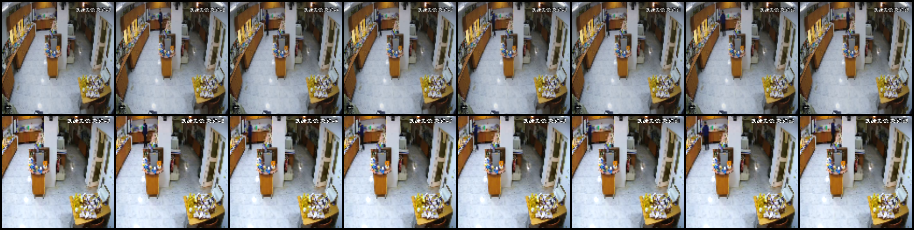

In [18]:
check(args)
from IPython.display import Image, display
display(Image('aug_check.png'))

### Train CNN + GRU

In [ ]:
args.arch = 'cnn_gru'
train(args)

classes=['non shop lifters', 'shop lifters']  positive class='shop lifters'  device=cuda
train=581 val=103 test=171
params: 1.47M
ep 01 loss=0.7415 | val acc=0.612 P=0.000 R=0.000 F1=0.000
ep 02 loss=0.7195 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 03 loss=0.7220 | val acc=0.621 P=0.000 R=0.000 F1=0.000
ep 04 loss=0.7125 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 05 loss=0.7080 | val acc=0.621 P=0.000 R=0.000 F1=0.000
ep 06 loss=0.6994 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 07 loss=0.7107 | val acc=0.621 P=0.000 R=0.000 F1=0.000
ep 08 loss=0.7075 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 09 loss=0.7007 | val acc=0.621 P=0.000 R=0.000 F1=0.000
ep 10 loss=0.7004 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 11 loss=0.7055 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 12 loss=0.6675 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 13 loss=0.6260 | val acc=0.748 P=0.633 R=0.795 F1=0.705
ep 14 loss=0.5934 | val acc=0.379 P=0.379 R=1.000 F1=0.549
ep 15 loss=0.5991 | val acc=0.379 P=0.379 R=

### Train 3D CNN (optional comparison)

In [20]:
args.arch = 'cnn3d'
train(args)

ep 06 loss=0.7116 | val acc=0.621 P=0.000 R=0.000 F1=0.000
ep 07 loss=0.7074 | val acc=0.631 P=1.000 R=0.026 F1=0.050
ep 08 loss=0.7051 | val acc=0.621 P=0.000 R=0.000 F1=0.000
ep 09 loss=0.7042 | val acc=0.660 P=0.534 R=0.795 F1=0.639
ep 10 loss=0.7073 | val acc=0.631 P=1.000 R=0.026 F1=0.050
ep 11 loss=0.6910 | val acc=0.650 P=0.552 R=0.410 F1=0.471
ep 12 loss=0.6944 | val acc=0.602 P=0.472 R=0.436 F1=0.453
ep 13 loss=0.6810 | val acc=0.592 P=0.459 R=0.436 F1=0.447
ep 14 loss=0.6714 | val acc=0.680 P=0.636 R=0.359 F1=0.459
ep 15 loss=0.6727 | val acc=0.670 P=0.647 R=0.282 F1=0.393
ep 16 loss=0.6446 | val acc=0.680 P=0.615 R=0.410 F1=0.492
ep 17 loss=0.6455 | val acc=0.650 P=0.552 R=0.410 F1=0.471
ep 18 loss=0.6070 | val acc=0.670 P=0.609 R=0.359 F1=0.452
ep 19 loss=0.6094 | val acc=0.680 P=0.615 R=0.410 F1=0.492
ep 20 loss=0.6062 | val acc=0.650 P=0.548 R=0.436 F1=0.486

=== TEST ===
accuracy=0.6959 precision=0.5631 recall=0.8923 f1=0.6905
[[61 45]
 [ 7 58]]
                  precisi